In [1]:
import numpy as np
import matplotlib.pyplot as plt 
import sys
import glob
plt.style.use("~/evanstyle.mplstyle") #change this if you want! or comment

sys.path.append('../WaveformPlotter/')
sys.path.append("../Acdc/")
import WaveformPlotter
import Acdc

In [ ]:

#this set of boards is used in the July 2024 proton data at test-beam
acdcs = {44:{"obj":None, "config":"../configs/acdc44.yml", "infiles": [], "pedfiles": []}, \
	43:{"obj":None, "config":"../configs/acdc43.yml", "infiles": [], "pedfiles": []}}

#Configure some data filepaths
#you'll likely want to keep paths as we may be committing/pushing
#multiple paths. Just use a comment
datadir = "/Volumes/CODEDRIVE/FTBF/ProtonJune2024/prereduced/"
print("Checking for files in datadir: ")
infiles = glob.glob(datadir + "*")
print(infiles)
infiles = []


Checking for files in datadir: 
['/Volumes/CODEDRIVE/FTBF/ProtonJune2024/prereduced/Raw_ProtonData_20240701_135251_b0_prereduced.p', '/Volumes/CODEDRIVE/FTBF/ProtonJune2024/prereduced/Raw_ProtonData_20240701_135251_b1_prereduced.p']


In [ ]:

#load the waveforms into the events attribute
just_acdc_objects = []
for acdc_num, a in acdcs.items():
	a["obj"] = Acdc.Acdc(a["config"])
	bnum = a["obj"].c["station_id"] 
	prereduced_files = glob.glob(datadir + f"*b{bnum}_prereduced.p")
	print(f"Found {len(prereduced_files)} prereduced files for board {bnum}")
	#just use one of the files
	print("Loading data from", prereduced_files[0])
	a["obj"].read_events_from_file(prereduced_files[0])
	a["obj"].load_default_times()
	just_acdc_objects.append(a["obj"])


#create the waveform plotter object
wp = WaveformPlotter.WaveformPlotter(just_acdc_objects)
	

/Volumes/CODEDRIVE/FTBF/ProtonJune2024/prereduced/*b0_prereduced.p
Found 1 prereduced files for board 0
Loading data from /Volumes/CODEDRIVE/FTBF/ProtonJune2024/prereduced/Raw_ProtonData_20240701_135251_b0_prereduced.p
/Volumes/CODEDRIVE/FTBF/ProtonJune2024/prereduced/*b1_prereduced.p
Found 1 prereduced files for board 1
Loading data from /Volumes/CODEDRIVE/FTBF/ProtonJune2024/prereduced/Raw_ProtonData_20240701_135251_b1_prereduced.p


KeyError: 'start_cap'

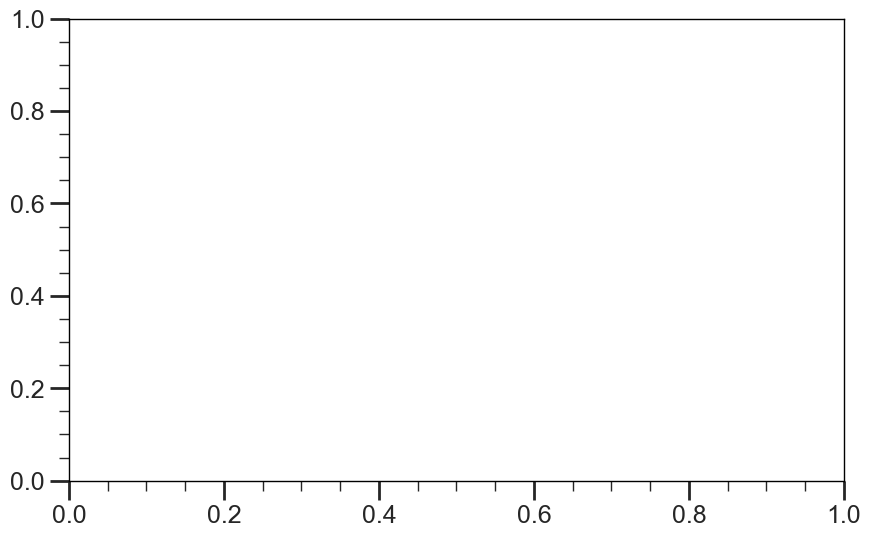

In [8]:
for i in range(10):
    fig, ax = wp.plot_waveforms_separated(station_id=1)
    #plt.savefig("../../plots/example_waveforms/{:d}_b0.png".format(i))
    plt.show()

for i in range(10, 20):
    fig, ax = wp.plot_waveforms_separated(station_id=0)
    #plt.savefig("../../plots/example_waveforms/{:d}_b1.png".format(i))
    plt.show()

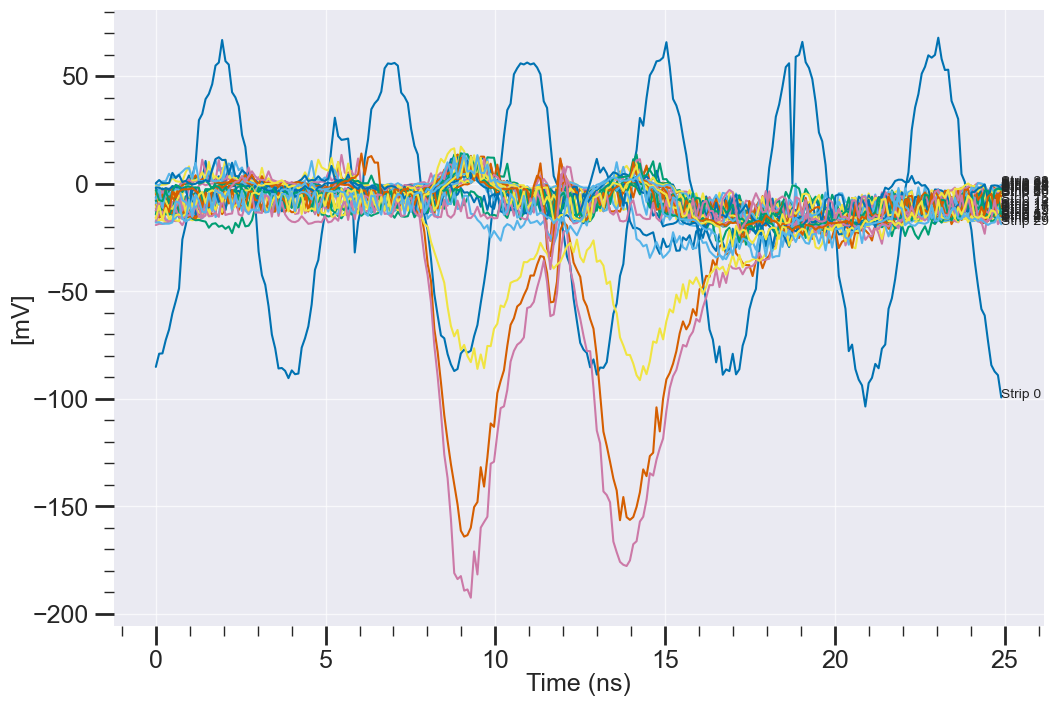

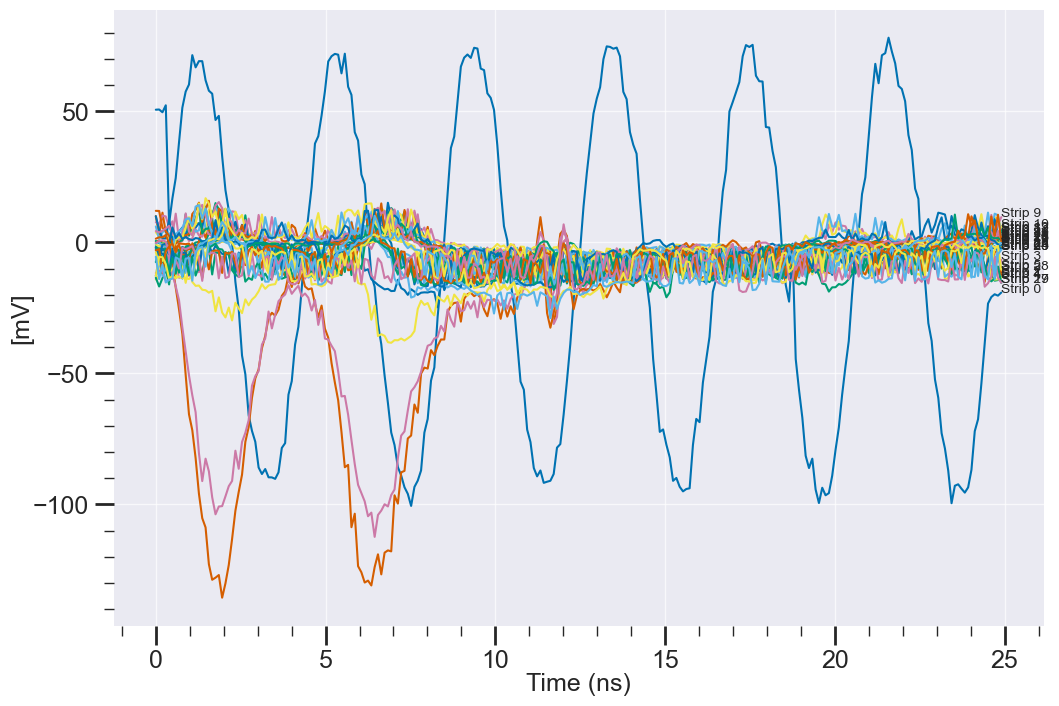

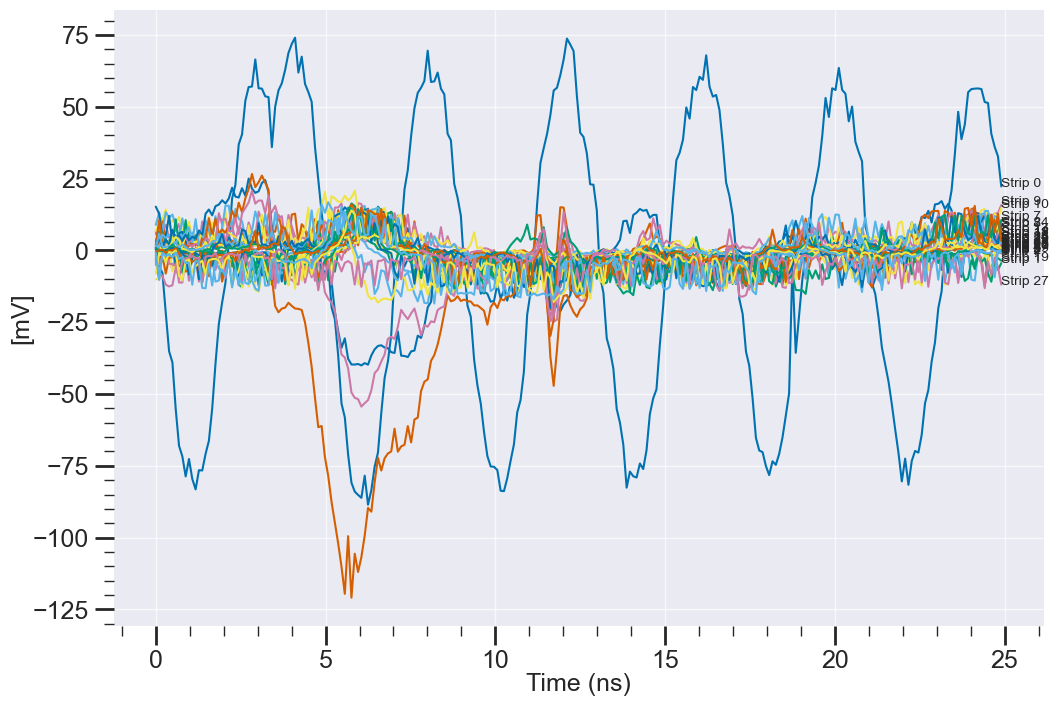

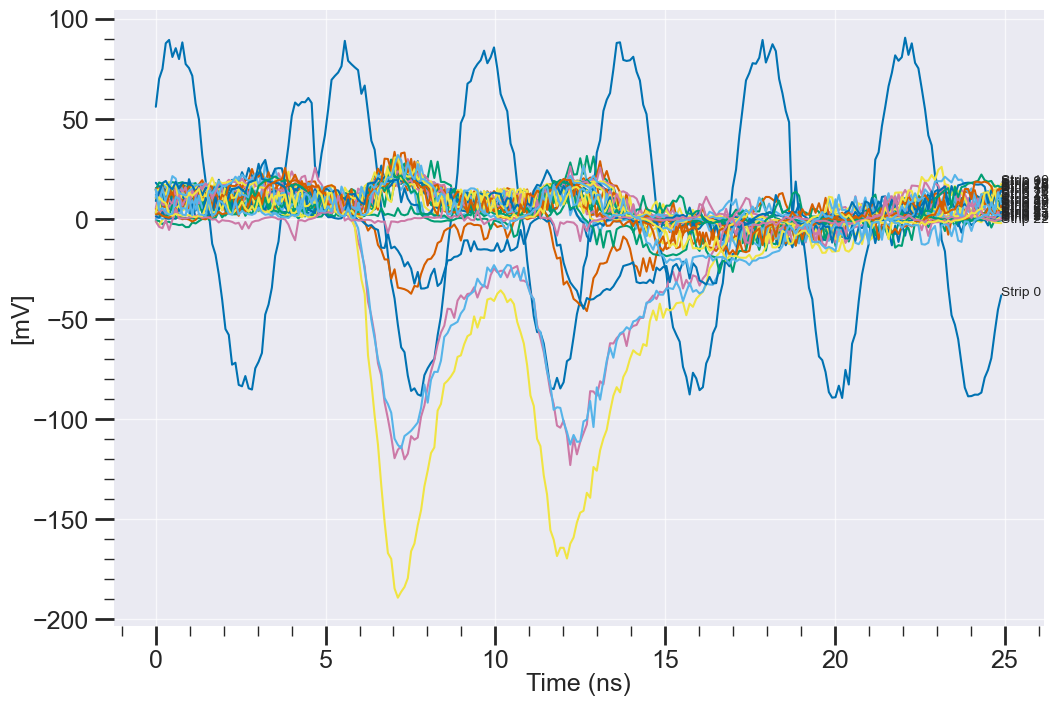

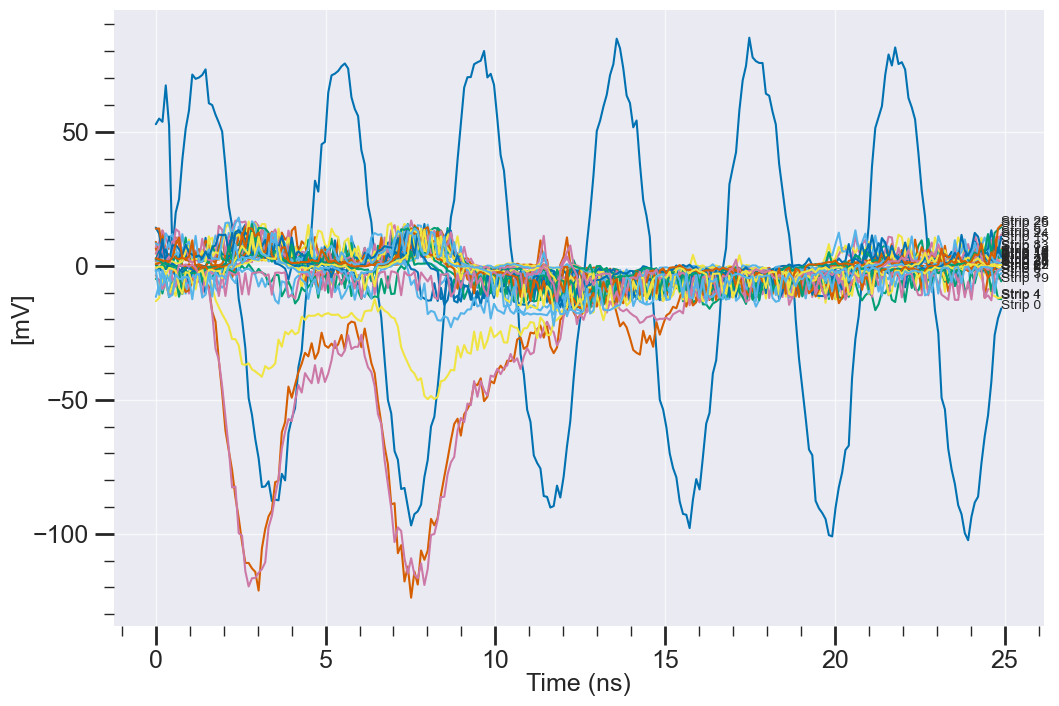

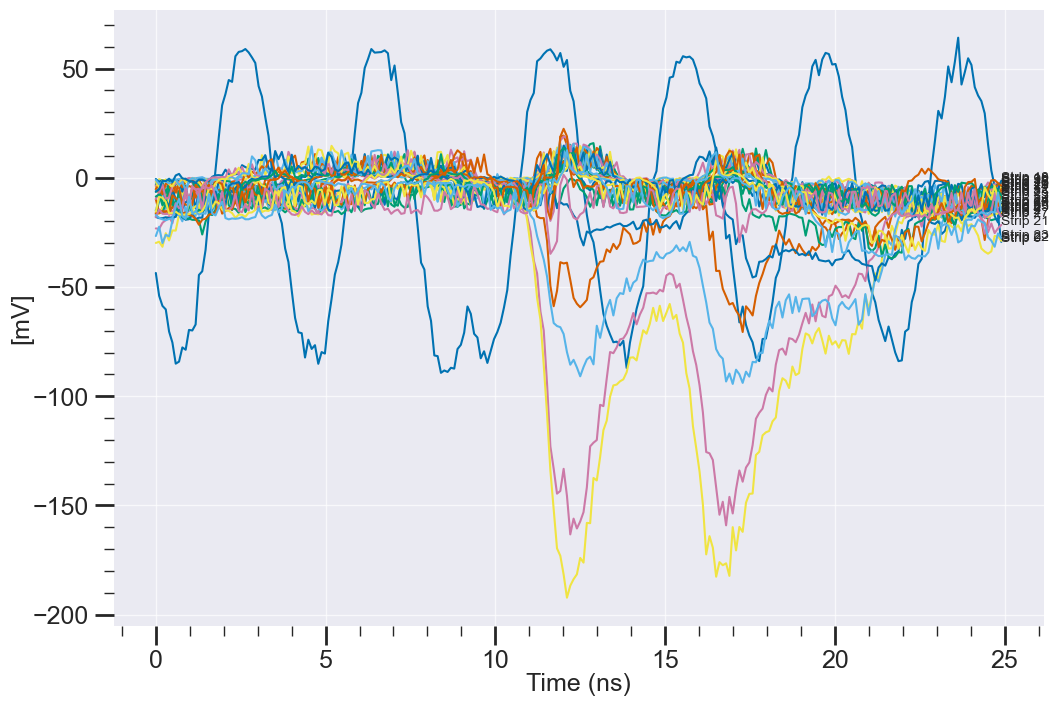

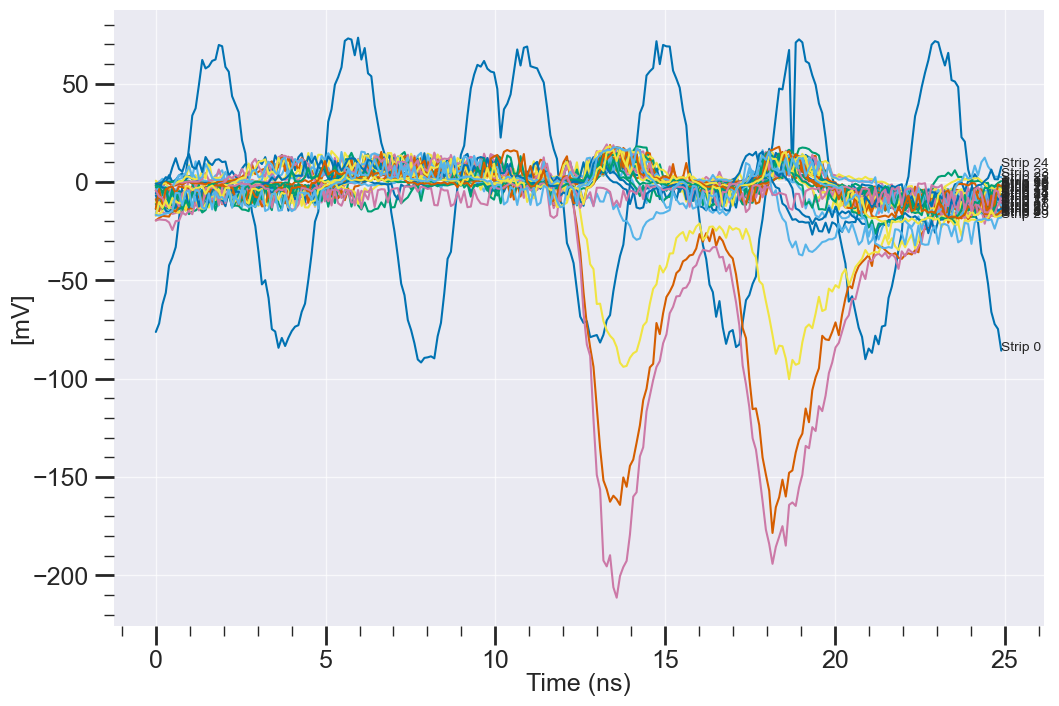

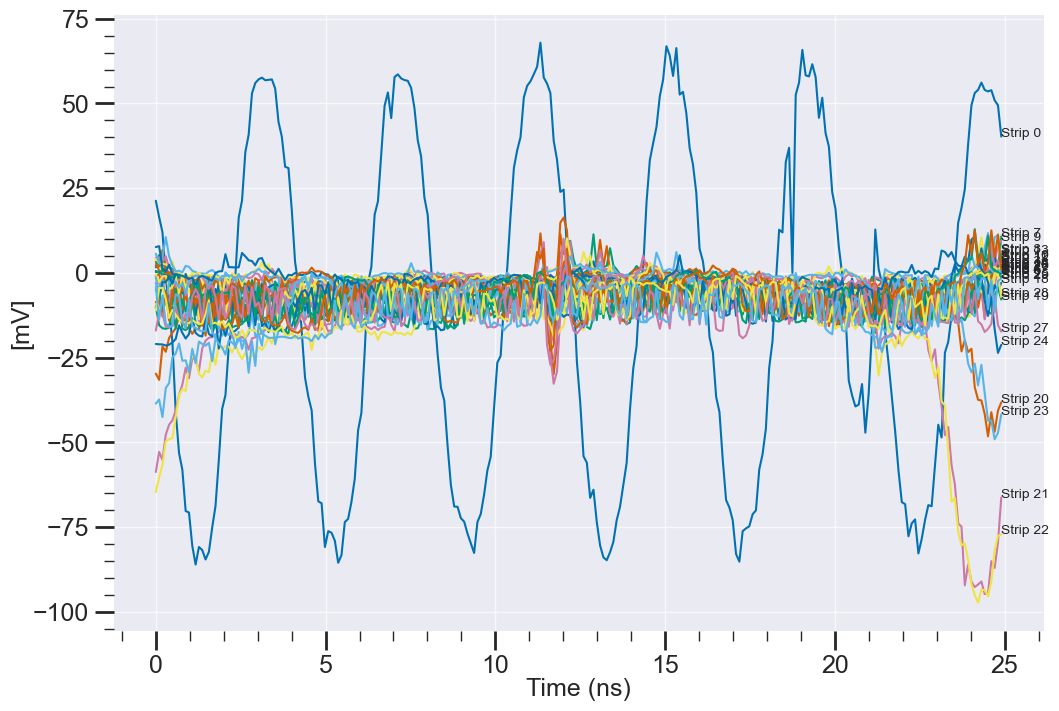

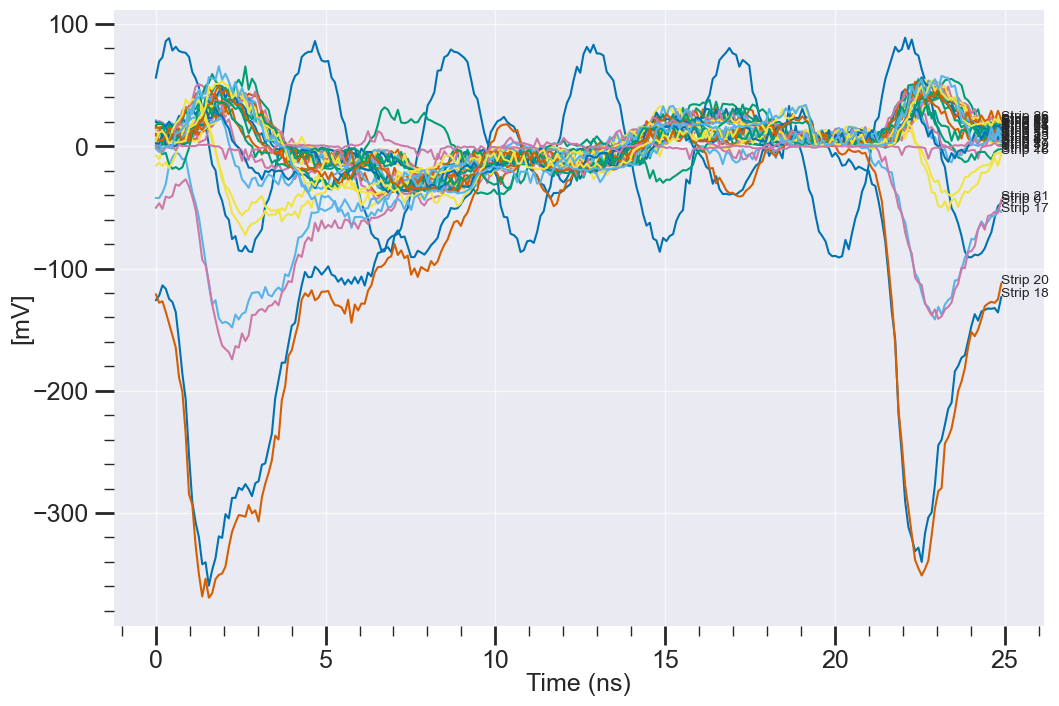

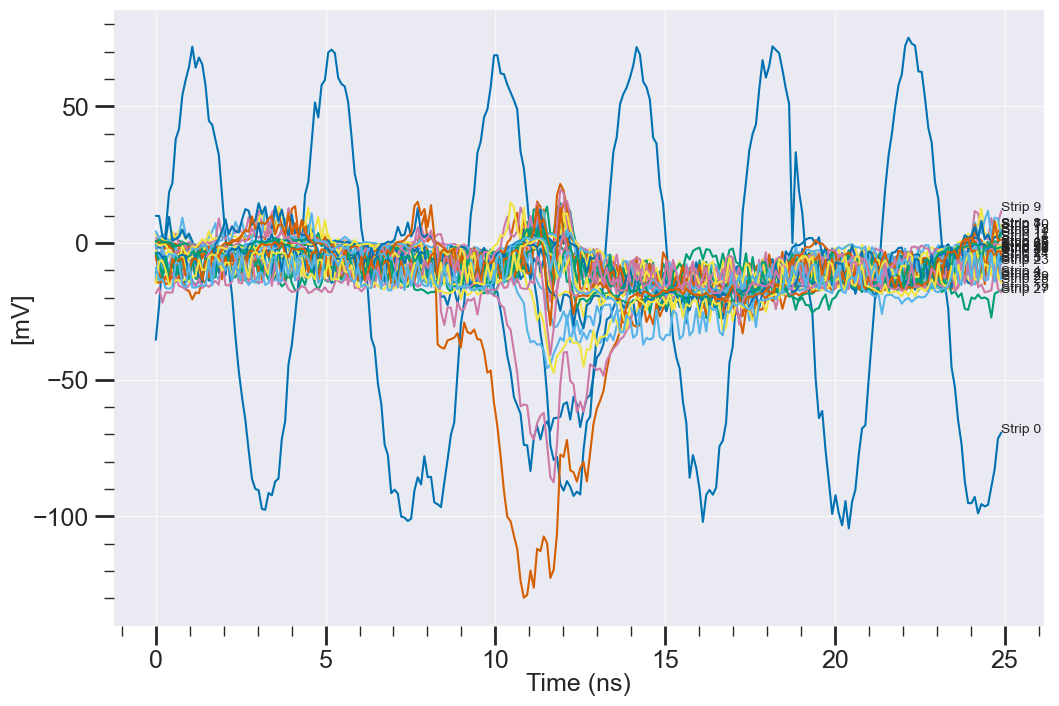

In [8]:
for i in range(10):
    fig, ax = wp.plot_waveforms_separated(sep=0, station_id=1)
    #plt.savefig("../../plots/example_waveforms/{:d}_b0.png".format(i))
    plt.show()